# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.


Of the people the model predicts have the disease, precision is the percentage who actually have it.

2. Explain what "recall" represents in this context.


Of the people who actually have the disease, recall is the percentage the model correctly predicts have it.

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

Failing to conclude that a person has the disease when they actually have it. That person goes untreated and the disease can get worse. Telling a healthy person they have the disease is also bad, but follow-up testing can catch and correct that mistake.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

Recall. Missed cases are the more serious error, so we want the model to catch as many people with the disease as possible.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

Less strict. The model should predict disease for more people, for example by lowering the probability threshold so fewer real cases are missed.

6. What is a downside to your choice in the previous part?

More healthy people will be predicted to have the disease so precision goes down. They face unnecessary stress, extra testing, and cost.

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


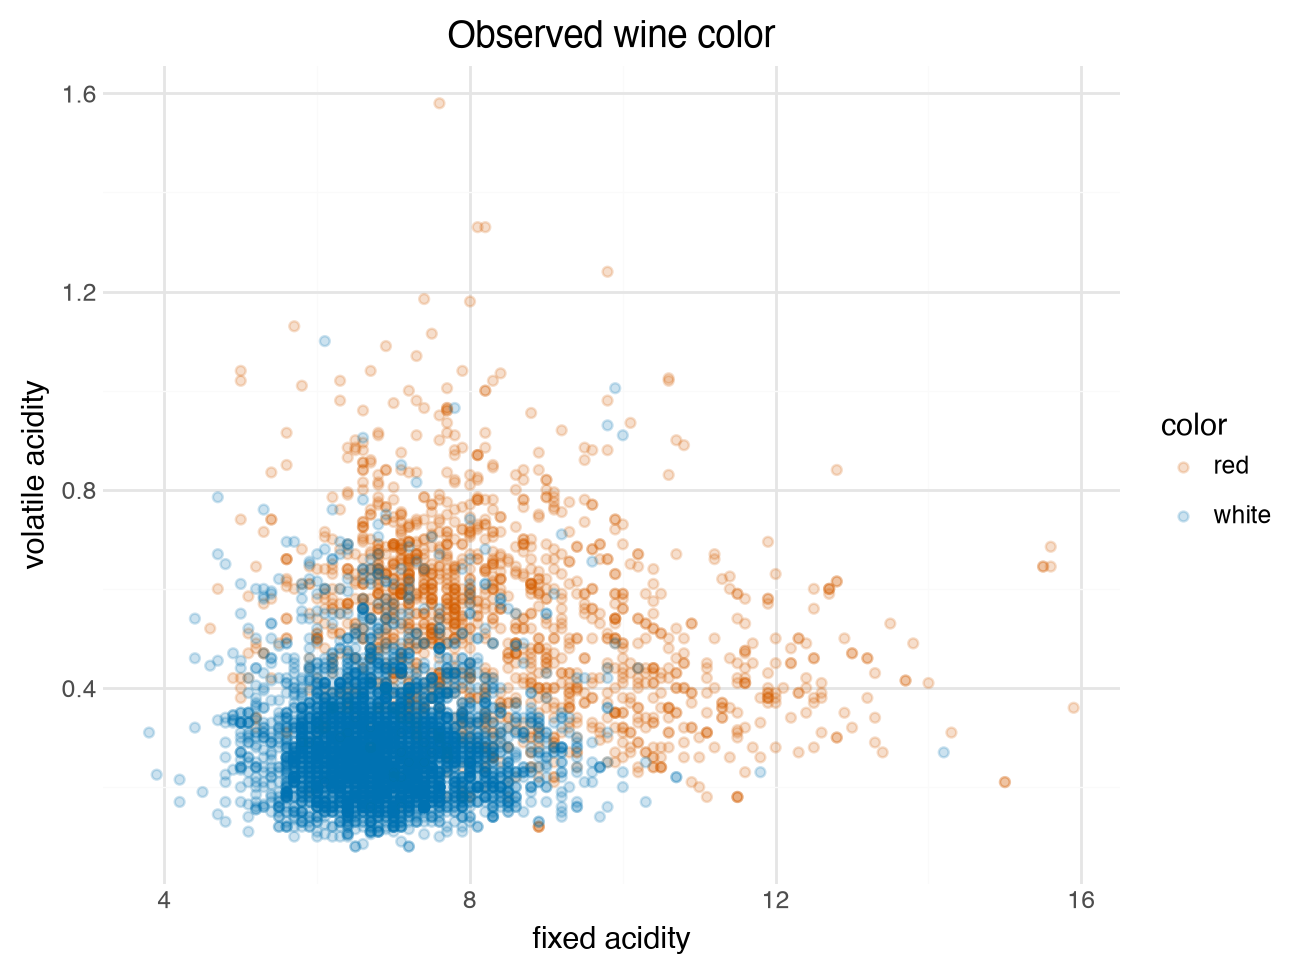

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

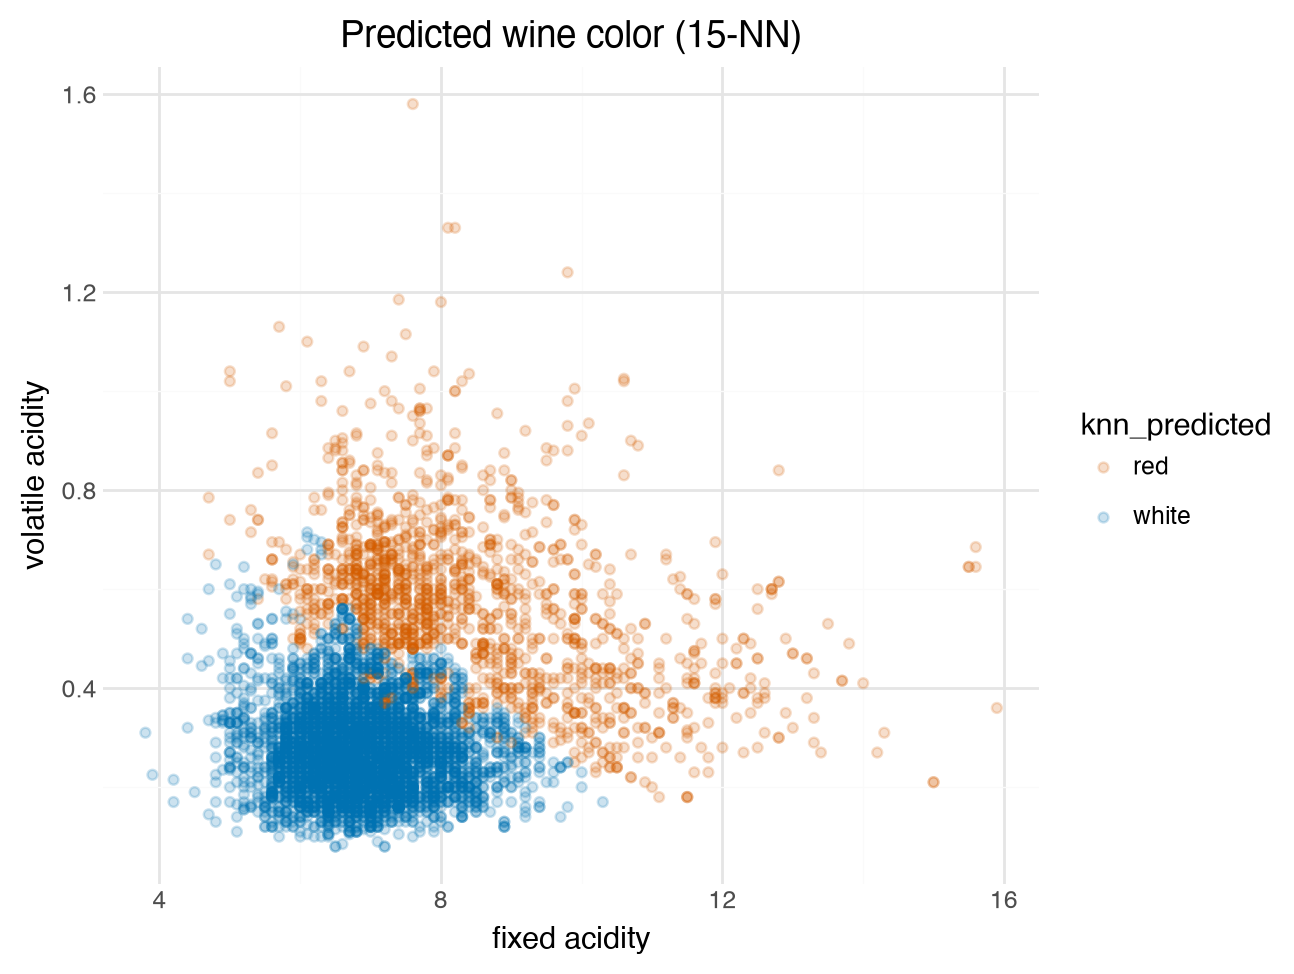

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X_train = df_train[["fixed acidity", "volatile acidity"]]
y_train = df_train["color"]

pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)
pipeline.fit(X_train, y_train)

df_train["knn_predicted"] = pipeline.predict(X_train)

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="knn_predicted"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (15-NN)")
    + theme_minimal()
)


The predicted plot matches the overall pattern of the observed plot. Wines with low volatile and fixed acidity are white, and wines with higher values are red. In the observed plot, some wines appear inside the other color’s region. The model gives each wine the majority color of its 15 neighbors, so the predicted plot shows two cleanly separated regions. The mixed-in wines are the ones the model gets wrong.

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [5]:
from sklearn.model_selection import cross_val_score

precision_macro = cross_val_score(pipeline, X_train, y_train,
                                  cv=10, scoring="precision_macro").mean()
recall_macro = cross_val_score(pipeline, X_train, y_train,
                               cv=10, scoring="recall_macro").mean()
f1_macro = cross_val_score(pipeline, X_train, y_train,
                           cv=10, scoring="f1_macro").mean()

precision_macro, recall_macro, f1_macro

(np.float64(0.8813805542523216),
 np.float64(0.8543688286606457),
 np.float64(0.8632968326738716))

The estimated test macro precision is 88.1%, macro recall is 85.4%, and macro F1 is 86.3%, averaged over red and white wines.

3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

{'kneighborsclassifier__n_neighbors': 16}


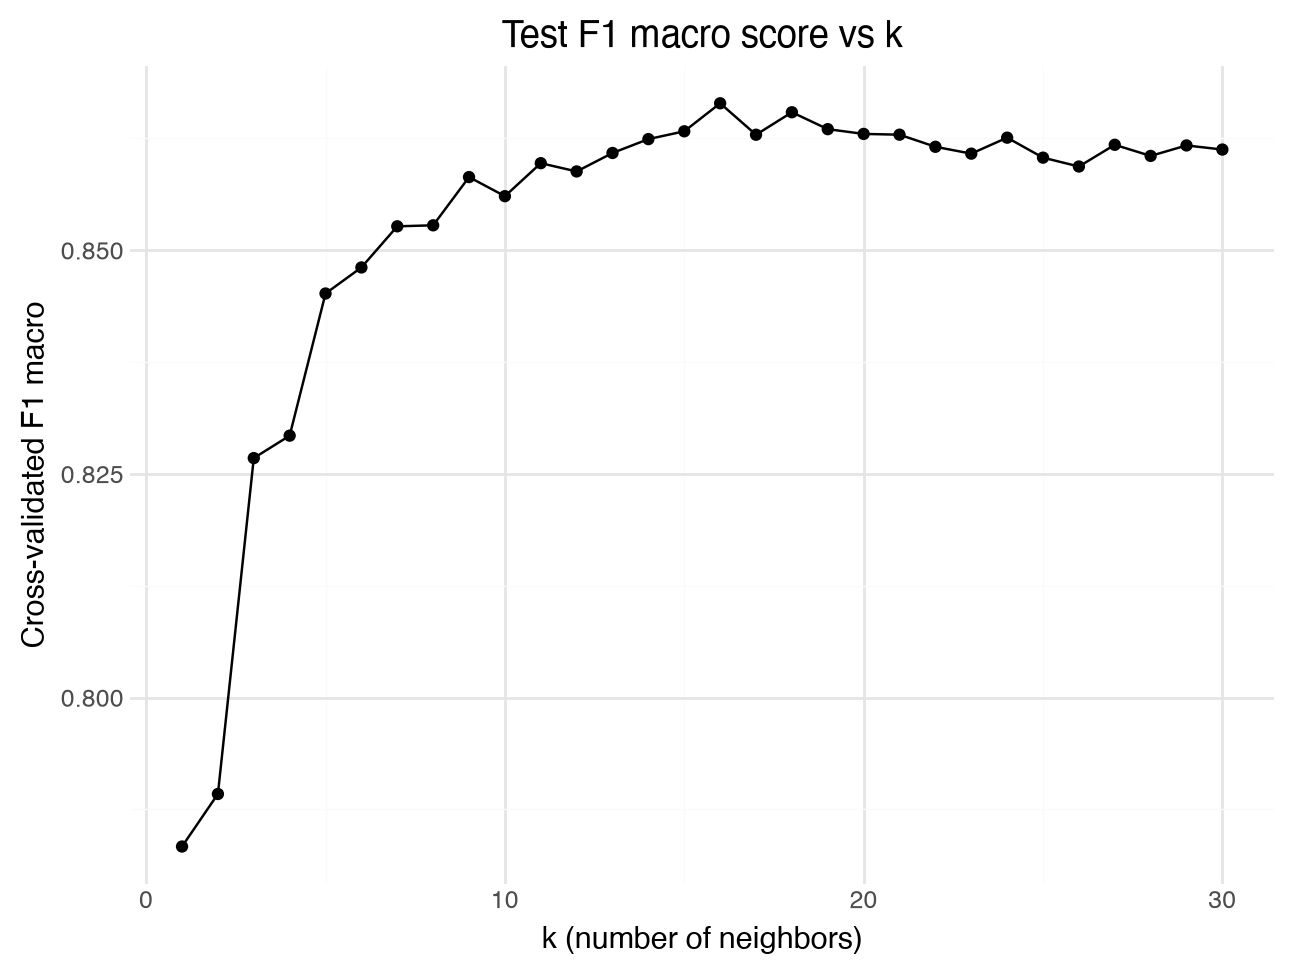

In [6]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    pipeline,
    param_grid={"kneighborsclassifier__n_neighbors": range(1, 31)},
    scoring="f1_macro",
    cv=10
)
grid_search.fit(X_train, y_train)

results = pd.DataFrame(grid_search.cv_results_)
results["k"] = results["param_kneighborsclassifier__n_neighbors"].astype(int)

print(grid_search.best_params_)

(
    ggplot(results, aes(x="k", y="mean_test_score"))
    + geom_line()
    + geom_point()
    + labs(x="k (number of neighbors)", y="Cross-validated F1 macro",
           title="Test F1 macro score vs k")
    + theme_minimal()
)

k = 16 gives the best cross-validated F1 macro score (about 0.867). The score rises quickly up to about k = 10, then levels off, so values from about 14 to 30 perform almost the same.

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

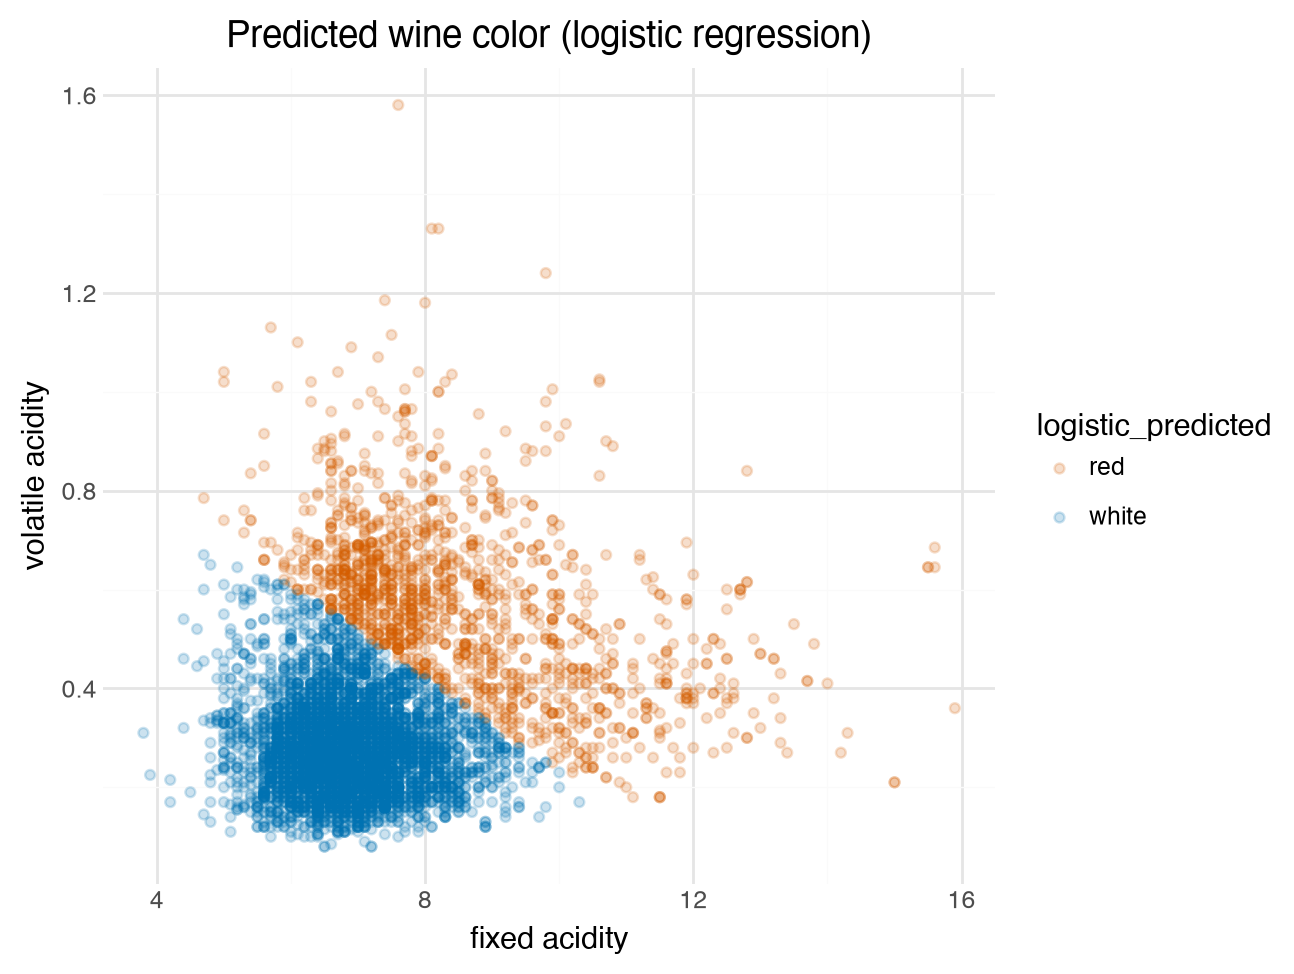

In [7]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

df_train["logistic_predicted"] = logistic_model.predict(X_train)

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="logistic_predicted"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (logistic regression)")
    + theme_minimal()
)

Both models predict white for wines with low fixed and volatile acidity and red for wines with higher values. The difference is the boundary. Logistic regression separates the colors with one straight line, while 15-NN draws an uneven boundary that follows the nearby points.

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [8]:
precision_log = cross_val_score(logistic_model, X_train, y_train,
                                cv=10, scoring="precision_macro").mean()
recall_log = cross_val_score(logistic_model, X_train, y_train,
                             cv=10, scoring="recall_macro").mean()
f1_log = cross_val_score(logistic_model, X_train, y_train,
                         cv=10, scoring="f1_macro").mean()

precision_log, recall_log, f1_log

(np.float64(0.8926197528116662),
 np.float64(0.8450644802717939),
 np.float64(0.8604201106403506))

The two models perform almost the same. Logistic regression has slightly higher precision, while 15-NN has slightly higher recall and F1. All the differences are about 1 percentage point or less, so neither model is clearly better with these two features.

6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [9]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X_all = df_train.drop(columns=["color", "knn_predicted", "logistic_predicted"])

ct = ColumnTransformer([
    ("dummify", OneHotEncoder(handle_unknown="ignore"),
     make_column_selector(dtype_include=object)),
    ("standardize", StandardScaler(),
     make_column_selector(dtype_include=np.number))
])

logistic_all = Pipeline([
    ("preprocessing", ct),
    ("logistic", LogisticRegression(max_iter=10000))
])

precision_all = cross_val_score(logistic_all, X_all, y_train, cv=10, scoring="precision_macro").mean()
recall_all = cross_val_score(logistic_all, X_all, y_train, cv=10, scoring="recall_macro").mean()
f1_all = cross_val_score(logistic_all, X_all, y_train, cv=10, scoring="f1_macro").mean()

precision_all, recall_all, f1_all

(np.float64(0.9918493214070534),
 np.float64(0.9903466258160863),
 np.float64(0.9910636842797598))

With all the chemical features, logistic regression’s estimated test scores are about 99%, up from about 85–89% with two features. The other chemical measurements separate red and white wines much better than acidity alone.

7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [ ]:
lasso_logistic = Pipeline([
    ("preprocessing", ct),
    ("logistic", LogisticRegression(l1_ratio=1, solver="saga", max_iter=10000))
])

precision_lasso = cross_val_score(lasso_logistic, X_all, y_train, cv=10, scoring="precision_macro").mean()
recall_lasso = cross_val_score(lasso_logistic, X_all, y_train, cv=10, scoring="recall_macro").mean()
f1_lasso = cross_val_score(lasso_logistic, X_all, y_train, cv=10, scoring="f1_macro").mean()

precision_lasso, recall_lasso, f1_lasso

(np.float64(0.9920475776961805),
 np.float64(0.9901361666324128),
 np.float64(0.9910575771392345))

The LASSO model scores almost exactly the same as the unpenalized model from Q6. The differences are in the fourth decimal place. Adding the l1 penalty doesn’t change estimated test performance here. LASSO can shrink some coefficients to zero, so it may reach the same accuracy using fewer features.